# 相干 DP-16QAM 光纤通信系统：从比特到误码率的完整教程

本 Notebook 是 `docs/仿真原理与DSP算法详解.md` 的交互式配套材料，用 `optsim` 包（`Python/optsim/`）里的函数**逐步**搭建一条相干偏振复用（PDM, Polarization-Division Multiplexing）QAM（Quadrature Amplitude Modulation）系统，而不是直接调用封装好的 `system.rx_dsp` 黑盒——目的是让每一步 DSP（Digital Signal Processing，数字信号处理）算法对信号产生的影响**可见、可对比**。

**内容安排**：

1. 发射端 DSP：比特 → QAM 星座 → 成帧 → 脉冲成形
2. 典型信道损伤的"指纹"：色散、频偏、相位噪声、偏振耦合各自如何让星座变形
3. 接收端 DSP 逐步演示：针对第 2 部分的每种损伤，展示对应算法如何把星座"修"回去
4. 完整系统仿真：真实光纤链路（多跨分步傅里叶法 SSFM）+ 全部收发机器件 + 一键 `rx_dsp`
5. 拓展实验：BER（误码率）-OSNR（光信噪比）曲线，仿真 vs 理论
6. 总结与延伸阅读

> 建议对照 `docs/仿真原理与DSP算法详解.md` 第 3–8 节阅读，文中公式与本 Notebook 的代码一一对应。

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # 让 Python 能找到 optsim 包
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']  # 支持中文标签
plt.rcParams['axes.unicode_minus'] = False

from optsim import tx, devices as dev, channel, dsp, metrics, plots
from optsim.params import fiber_params
from optsim.utils import normalize, awgn, delay

rng = np.random.default_rng(2026)   # 全局随机数发生器，保证可复现
print('optsim 模块加载完成')

optsim 模块加载完成


## 第零部分：光纤通信与相干光通信基础知识导读

在动手跑代码之前，本节系统梳理一遍背景知识：调制解调原理、专业名词、数学物理基础、典型器件参数，以及结果判读与故障排查思路。已经熟悉这些内容的读者可以直接跳到第一部分；建议至少浏览一遍 0.5–0.6 节的名词与指标关系，后文会反复用到。

### 0.1 光纤通信系统的演进：从 OOK 到相干 QAM

| 年代（大致） | 调制/检测方式 | 典型速率 | 核心限制 |
|---|---|---|---|
| 1980s–1990s | OOK（On-Off Keying，通断键控）+ 直接检测（DD, Direct Detection） | 2.5–10 Gb/s | 接收机灵敏度低，只能用强度信息，色散容限很小 |
| 2000s | 差分相移键控 DPSK/DQPSK + 直接检测 | 10–40 Gb/s | 用相位编码提升灵敏度，但仍是模拟延时线解调，无法做数字均衡 |
| 2008 至今 | **相干检测**（Coherent Detection）+ 数字信号处理（DSP）+ 偏振复用 QAM | 100 Gb/s–1 Tb/s/波长 | 本文档的主题：用本振激光器 + 90° 光混频器把光场的**幅度和相位**都变换到电域，交给数字电路做均衡/补偿 |

相干检测相对直接检测的本质优势：直接检测只能恢复光功率 $|E|^2$（信息只在强度里），相干检测恢复的是**完整复光场** $E=|E|e^{j\phi}$（含相位、偏振信息），因此：
- 可以用相位和偏振承载更多比特（QAM、偏振复用），**频谱效率**大幅提升；
- 色散、偏振模色散这类**线性**损伤在电域可以用数字滤波器精确求逆补偿（本振提供了做相干解调所需的相位参考）；
- 本振光功率远大于信号光，拍频后的电信号被"放大"到远超热噪声的水平，接收机灵敏度逼近**量子极限**（散粒噪声限）。

### 0.2 数字调制与编码方式

**调制**（Modulation）：把比特序列映射成携带信息的物理波形（这里是光场的幅度/相位）。**解调**（Demodulation）是逆过程：从接收波形恢复比特。常见数字调制族：

- **OOK**（通断键控）：1 比特/符号，只用强度，最简单但频谱效率最低；
- **PAM-M**（Pulse Amplitude Modulation，脉冲幅度调制）：$\log_2 M$ 比特/符号，M 个实数电平，常用于 IM-DD（强度调制直接检测）系统（如 PAM4）；
- **PSK-M**（Phase Shift Keying，相移键控）：$\log_2 M$ 比特/符号，M 个等幅不同相位的点，恒包络（对非线性/放大器更友好）；
- **QAM-M**（本 Notebook 主角）：同时调制幅度和相位，$\log_2 M$ 比特/符号，频谱效率随 $M$ 增大而提升，但星座点间距变小、需要更高 SNR 才能达到同样误码率（详见 0.5 节）。

**格雷编码**（Gray Coding）：给相邻星座点分配仅相差 1 bit 的标签，使得"判决到最近的错误邻居"这种最常见的错误类型只产生 1 个误比特，而不是多个——这是所有实用数字调制系统的标准做法（本仓库 `tx.qam`/`tx.pam`/`tx.psk` 均已内置）。

**符号率 vs 比特率 vs 频谱效率**：
$$R_b = R_s\cdot\log_2 M \cdot N_{\text{pol}}, \qquad \text{频谱效率} \approx \frac{R_b}{B}\ [\text{bit/s/Hz}]$$
其中 $R_s$ 为符号率（Baud, Bd）、$R_b$ 为比特率、$N_{\text{pol}}=2$（偏振复用）、$B\approx(1+\beta)R_s$ 为占用带宽（$\beta$ 为脉冲成形滚降系数，见文档 §3.5）。例如 32 GBd 的 DP-16QAM：$R_b=32\times4\times2=256$ Gb/s。

下面用代码直观对比几种调制格式的星座图与比特数/符号：

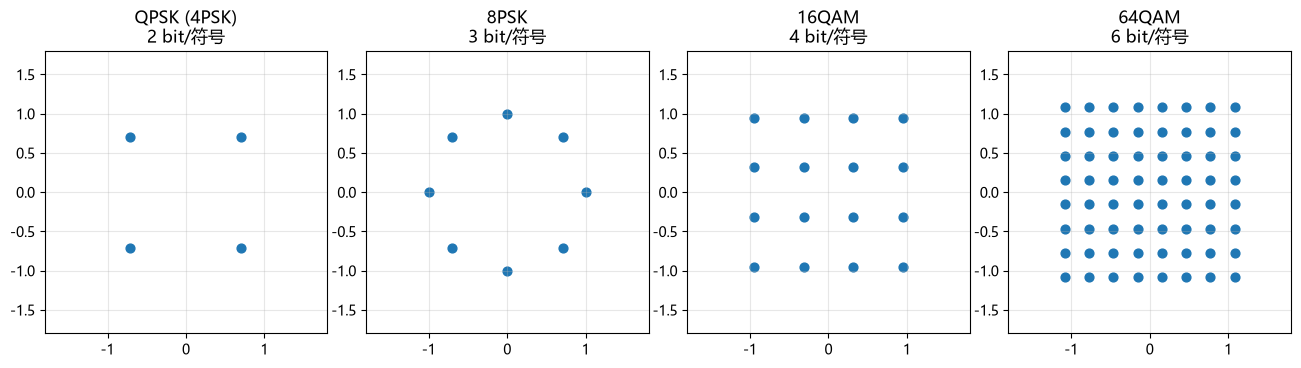

达到 BER=1e-3 所需的每符号 SNR（dB，AWGN 信道理论值，直观体会"阶数越高、对 SNR 要求越苛刻"）：
    4PSK（2 bit/符号）：约需 SNR ≈   9.8 dB
    8PSK（3 bit/符号）：约需 SNR ≈  14.8 dB
   16QAM（4 bit/符号）：约需 SNR ≈  16.5 dB
   64QAM（6 bit/符号）：约需 SNR ≈  22.5 dB
  256QAM（8 bit/符号）：约需 SNR ≈  28.4 dB


In [2]:
# 调制格式对比：星座图 + 比特数/符号 + （信息论上）达到相同误码率所需的相对 SNR
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
formats = [('QPSK (4PSK)', tx.psk(4)), ('8PSK', tx.psk(8)), ('16QAM', tx.qam(16)), ('64QAM', tx.qam(64))]
for ax, (name, cc) in zip(axes, formats):
    ax.scatter(cc.real, cc.imag, s=40)
    ax.set_title(f'{name}\n{int(np.log2(len(cc)))} bit/符号'); ax.set_aspect('equal'); ax.grid(alpha=.3)
    ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.8)
plt.tight_layout(); plt.show()

print('达到 BER=1e-3 所需的每符号 SNR（dB，AWGN 信道理论值，直观体会"阶数越高、对 SNR 要求越苛刻"）：')
for M, kind in [(4,'psk'), (8,'psk'), (16,'qam'), (64,'qam'), (256,'qam')]:
    snr_grid = np.linspace(0, 30, 3000)
    ber = metrics.ber_theory(M, snr_grid, kind)
    snr_req = snr_grid[np.argmin(np.abs(ber - 1e-3))]
    print(f'  {M:>3d}{"PSK" if kind=="psk" else "QAM"}（{int(np.log2(M))} bit/符号）：约需 SNR ≈ {snr_req:5.1f} dB')

### 0.3 相干探测的数学原理

设信号光场 $E_s(t)=\sqrt{P_s}e^{j(\omega_s t+\phi_s(t))}$，本振光场 $E_{LO}(t)=\sqrt{P_{LO}}e^{j(\omega_{LO}t+\phi_{LO}(t))}$。经 90° 光混频器 + 平衡探测器后（文档 §7.1），输出电流正比于两者的拍频项：

$$i_I\propto\mathrm{Re}\{E_sE_{LO}^*\} = \sqrt{P_sP_{LO}}\cos\big[(\omega_s-\omega_{LO})t+\phi_s-\phi_{LO}\big],\qquad
i_Q\propto\mathrm{Im}\{E_sE_{LO}^*\}$$

**关键点**：
1. 拍频项幅度 $\propto\sqrt{P_sP_{LO}}$——本振功率 $P_{LO}$ 越大，有用信号相对于热噪声的增益越大（"本振增益"），这是相干接收机灵敏度优于直接检测的根本原因；
2. $\omega_s-\omega_{LO}$ 就是接收端看到的**频偏**（第 8.6 节 FOE 要估计的量）；若 $\omega_s=\omega_{LO}$ 则称为**零差检测**（homodyne），否则为**外差/内差检测**（heterodyne/intradyne）——现代相干系统几乎都用内差检测（允许小频偏，DSP 补偿，无需本振锁相环硬件跟踪到零频偏）；
3. $\phi_s-\phi_{LO}$ 就是接收端看到的**相位**，包含了两个激光器各自独立的相位噪声之和——这就是为什么第 8.7 节的载波相位恢复要同时跟踪发射和接收两个激光器的合成线宽（通常取两者之和作为等效线宽）。

**偏振复用的数学表示**：用琼斯矢量（Jones Vector）$\mathbf E=[E_x,E_y]^T$ 描述双偏振光场，光纤中的偏振演化（随机旋转 + PMD）用 $2\times2$ 幺正矩阵（Jones Matrix，`devices.random_unitary`）作用：$\mathbf E_{\text{out}}=\mathbf U(z)\mathbf E_{\text{in}}$。接收端恰好需要一个逆矩阵把两偏振解耦——这正是 2×2 MIMO 均衡器（文档 §8.5）要自适应学习的东西。

### 0.4 光纤传输物理基础速查

详细推导见文档 §5；这里给出"一张图记住"的核心公式与直觉数字：

| 效应 | 核心公式 | 数量级直觉（C 波段 SSMF） |
|---|---|---|
| 损耗 | $P(L)=P_0\cdot10^{-\alpha L/10}$ | $\alpha\approx0.2$ dB/km，80 km 一跨衰减 16 dB |
| 群速度色散 GVD | 脉冲展宽 $\Delta t\approx D\cdot L\cdot\Delta\lambda$（或等效地用 $\beta_2$ 描述频率色散） | $D\approx17$ ps/(nm·km)；32 GBd 信号（谱宽 ~32 GHz ≈ 0.26 nm）传 80 km 后展宽约数十 ps——已经超过一个符号周期（31 ps），必须靠 DSP 补偿，不能靠对齐时钟解决 |
| 自相位调制 SPM | 非线性相移 $\phi_{\text{NL}}=\gamma P L_{\text{eff}}$ | $\gamma\approx1.3$ 1/(W·km)；1 mW 恒定功率传 20 km（$L_{\text{eff}}\approx20$ km）约产生 0.026 rad 的相移，实际信号功率更高、非线性效应累积更明显 |
| 四波混频 FWM | 需满足相位匹配：色散越小，相位失配越小，FWM 越强 | 这就是为什么色散位移光纤 DSF（C 波段 $D\approx0$）里 FWM 比 SSMF 强约 1000 倍（见文档 §5.1 与自检 FWM 测试） |
| PMD | 一阶 PMD 用差分群时延 DGD 描述，统计上 $\langle\Delta\tau\rangle=D_{\text{PMD}}\sqrt L$ | $D_{\text{PMD}}\approx0.05$ ps/√km（现代光纤），1000 km 后平均 DGD ≈ 1.6 ps，对 32 GBd（符号周期 31 ps）影响很小；老光纤/长距离下可能成为瓶颈 |

**一个重要的工程直觉**：色散是**确定性、线性**的（只要知道光纤长度就能精确求逆补偿，文档 §8.2 的 CDC），而 Kerr 非线性是**功率依赖、非线性**的（不能用简单的逆滤波器完全补偿，这就是为什么"最优入纤功率"存在——功率太低则 ASE 噪声主导，太高则非线性失真主导，详见 `examples/launch_power_sweep.py` 与 GN 模型，文档 §6.3）。

### 0.5 噪声来源、性能指标与它们的关系链条

| 噪声/损伤来源 | 产生于 | 统计特性 | 对应仿真函数 |
|---|---|---|---|
| 放大自发辐射 ASE | 每个光放大器（EDFA 等） | 加性复高斯白噪声，随跨数累积 | `devices.edfa`、`devices.ase_psd` |
| 散粒噪声 shot noise | 光电探测器（光的量子特性） | 方差 $\propto$ 平均光电流 | `devices.photodiode` |
| 热噪声 thermal noise | 跨阻放大器/负载电阻 | 与信号无关的高斯白噪声 | `devices.photodiode` |
| 量化噪声 | DAC/ADC 有限分辨率（ENOB） | 近似均匀分布，等效 SNR $\approx6.02\times\text{ENOB}+1.76$ dB | `devices.dac`/`devices.adc` |
| 激光相位噪声 | 激光器有限线宽 $\Delta\nu$ | 维纳过程，随时间扩散 | `devices.laser` |
| 非线性相位噪声 | ASE 与信号功率在非线性光纤中的相互作用（Gordon–Mollenauer 效应） | 与信号瞬时功率相关，星座外圈点受影响更大 | 多跨 `channel.link` 自然产生 |
| 非线性干扰 NLI | Kerr 效应（SPM/XPM/FWM） | 高斯噪声模型（GN）近似为等效加性噪声 | `channel.gn_model` |

**指标之间的换算链条**（从光域到比特域）：

$$\text{OSNR（光域）}\ \xrightarrow{\text{文档 §10 公式}}\ \text{SNR（电域，每偏振符号）}\ \xrightarrow{\text{星座大小 }M}\ \text{BER（理论/实测）}\ \xrightarrow{\text{Q 因子换算}}\ Q\text{-factor}$$
$$\text{SNR} + \text{星座先验（可选 PCS）}\ \xrightarrow{\text{文档 §10 GMI 公式}}\ \text{GMI（可达速率，决定 FEC 之后能不能跑通）}$$

一个关键认识：**BER 本身不是最终目标，GMI 才是**——现代系统用软判决前向纠错（SD-FEC），只要 GMI 超过 FEC 码率对应的门限（典型约 20% 开销 SD-FEC 门限 GMI/$\log_2 M\approx0.8$ 左右，具体取决于编码方案），纠错后误码率可以降到 $10^{-15}$ 量级，所以工程上常直接比较 **GMI 对香农极限 $\log_2(1+\mathrm{SNR})$ 的差距**，而不是裸 BER。

### 0.6 专业名词速查（基础篇，更完整的 DSP 专有名词表见本 Notebook 末尾）

| 中文 | 英文缩写/全称 | 一句话解释 |
|---|---|---|
| 符号率 / 波特率 | Baud rate / symbol rate ($R_s$) | 每秒传输的符号个数，单位 Baud (Bd) |
| 比特率 | Bit rate ($R_b$) | 每秒传输的信息比特数，$R_b=R_s\log_2M\cdot N_{\text{pol}}$ |
| 频谱效率 | Spectral Efficiency (SE) | 单位带宽承载的比特率 [bit/s/Hz] |
| 背靠背 | B2B (Back-to-Back) | 发射机直接接收机对接、不经过光纤链路的测试配置，用于标定收发机本身的实现代价 |
| 实现代价 | Implementation Penalty | 实际系统达到某 BER 所需 OSNR 相对理论值多出的部分，来自器件非理想性、DSP 算法不完美 |
| 前向纠错 | FEC (Forward Error Correction) | 发射端加冗余编码，接收端自动纠错，分硬判决 HD-FEC（阈值判决输入）与软判决 SD-FEC（LLR 输入，性能更好） |
| 本振 | LO (Local Oscillator) | 相干接收机内部的参考激光器 |
| 波分复用 | WDM (Wavelength-Division Multiplexing) | 多个波长（信道）共享一根光纤同时传输 |
| 光信噪比 | OSNR (Optical SNR) | 光域信号功率与噪声功率之比，通常归一到 0.1 nm (12.5 GHz) 参考带宽 |

---

## 第一部分：发射端 DSP（Tx DSP）

对应文档 §3。流程：**比特 → Gray 映射 QAM → 成帧（训练+导频）→ 根升余弦（RRC）脉冲成形**。

16QAM 星座点数 = 16，平均功率 = 1.000（应为 1）


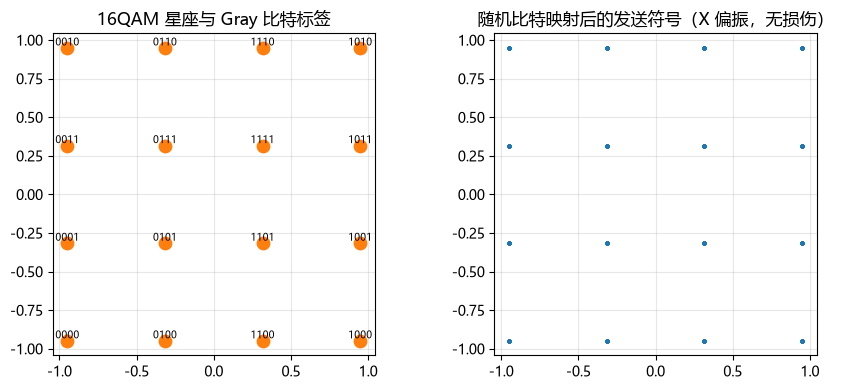

In [3]:
# ---- 1.1 比特与星座映射 ----
M = 16                                  # 16QAM
const = tx.qam(M)                       # Gray 映射，单位平均功率
print(f'16QAM 星座点数 = {len(const)}，平均功率 = {np.mean(np.abs(const)**2):.3f}（应为 1）')

bits = tx.rand_bits((2, 4000 * 4), rng)  # 双偏振，每符号 4 bit（log2(16)）
sym = tx.modulate(bits, const)           # (2, 4000) 复符号

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].scatter(const.real, const.imag, c='C1', s=80, zorder=3)
for lab, c in enumerate(const):
    ax[0].annotate(format(lab, '04b'), (c.real, c.imag), fontsize=7, ha='center', va='bottom')
ax[0].set_title('16QAM 星座与 Gray 比特标签'); ax[0].set_aspect('equal'); ax[0].grid(alpha=.3)
ax[1].scatter(sym[0].real, sym[0].imag, s=4, alpha=.5)
ax[1].set_title('随机比特映射后的发送符号（X 偏振，无损伤）'); ax[1].set_aspect('equal'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

帧总长度 = 4416 符号（训练 256 + 数据/导频 4160）


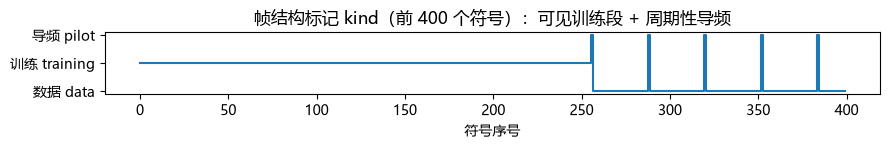

In [4]:
# ---- 1.2 成帧：训练序列 + 周期性导频 ----
period = 32                              # 每 32 个符号 1 个导频
train = const[rng.integers(0, M, (2, 256))]
pilot = const[rng.integers(0, M, (2, 200))]
frame, kind = tx.frame(sym, train, pilot, period)
print(f'帧总长度 = {frame.shape[1]} 符号（训练 {train.shape[1]} + 数据/导频 {frame.shape[1]-train.shape[1]}）')

plt.figure(figsize=(9, 1.6))
plt.plot(kind[:400], drawstyle='steps-mid')
plt.yticks([0, 1, 2], ['数据 data', '训练 training', '导频 pilot'])
plt.xlabel('符号序号'); plt.title('帧结构标记 kind（前 400 个符号）：可见训练段 + 周期性导频')
plt.tight_layout(); plt.show()

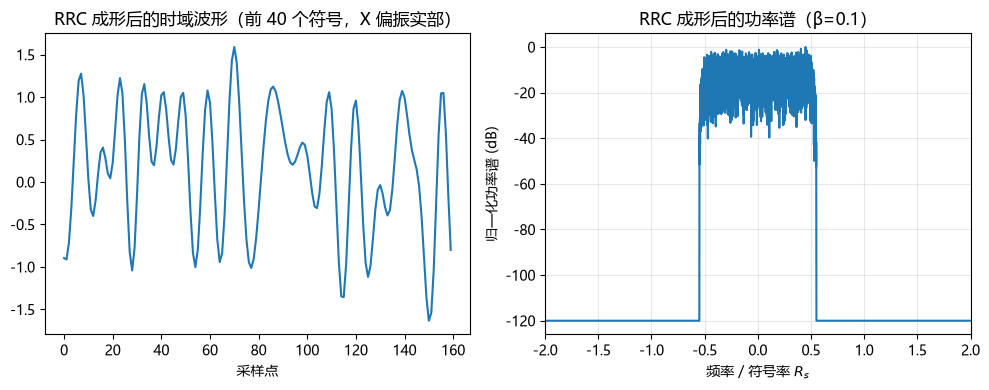

提示：带宽 ≈ (1+β)·符号率，图中主瓣半宽 ≈ 0.55 ×Rs


In [5]:
# ---- 1.3 根升余弦（RRC）脉冲成形：时域展宽、频域带限 ----
sps = 4                                  # 每符号采样点数
beta = 0.1                               # 滚降系数
wave = normalize(tx.pulse_shape(frame, sps, beta))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(np.real(wave[0, :40*sps]))
ax[0].set_title('RRC 成形后的时域波形（前 40 个符号，X 偏振实部）'); ax[0].set_xlabel('采样点')

# 频谱按"符号率的倍数"归一化显示（未绑定具体 Hz 单位，脉冲成形只关心相对带宽）
f_norm = np.fft.fftshift(np.fft.fftfreq(wave.shape[-1], d=1/sps))   # 单位：×符号率 Rs
psd = np.abs(np.fft.fftshift(np.fft.fft(wave[0])))**2
ax[1].plot(f_norm, 10*np.log10(psd/psd.max() + 1e-12))
ax[1].set_xlim(-2, 2); ax[1].set_xlabel('频率 / 符号率 $R_s$'); ax[1].set_ylabel('归一化功率谱 (dB)')
ax[1].set_title(f'RRC 成形后的功率谱（β={beta}）'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print('提示：带宽 ≈ (1+β)·符号率，图中主瓣半宽 ≈', (1+beta)/2, '×Rs')

## 第二部分：典型信道损伤的"指纹"

在接触完整光纤链路之前，先用**理想 AWGN（加性高斯白噪声）信道 + 单项注入损伤**的方式，直观看看色散、频偏、相位噪声、偏振耦合各自会把星座变成什么样子。这是理解"为什么接收端需要这些 DSP 模块"的关键——每个模块都是为了消除某一种特征性的失真。

对应文档 §5.1（色散/非线性）、§8.6（频偏）、§8.7（相位噪声/CPR）、§8.5（偏振耦合/MIMO）。

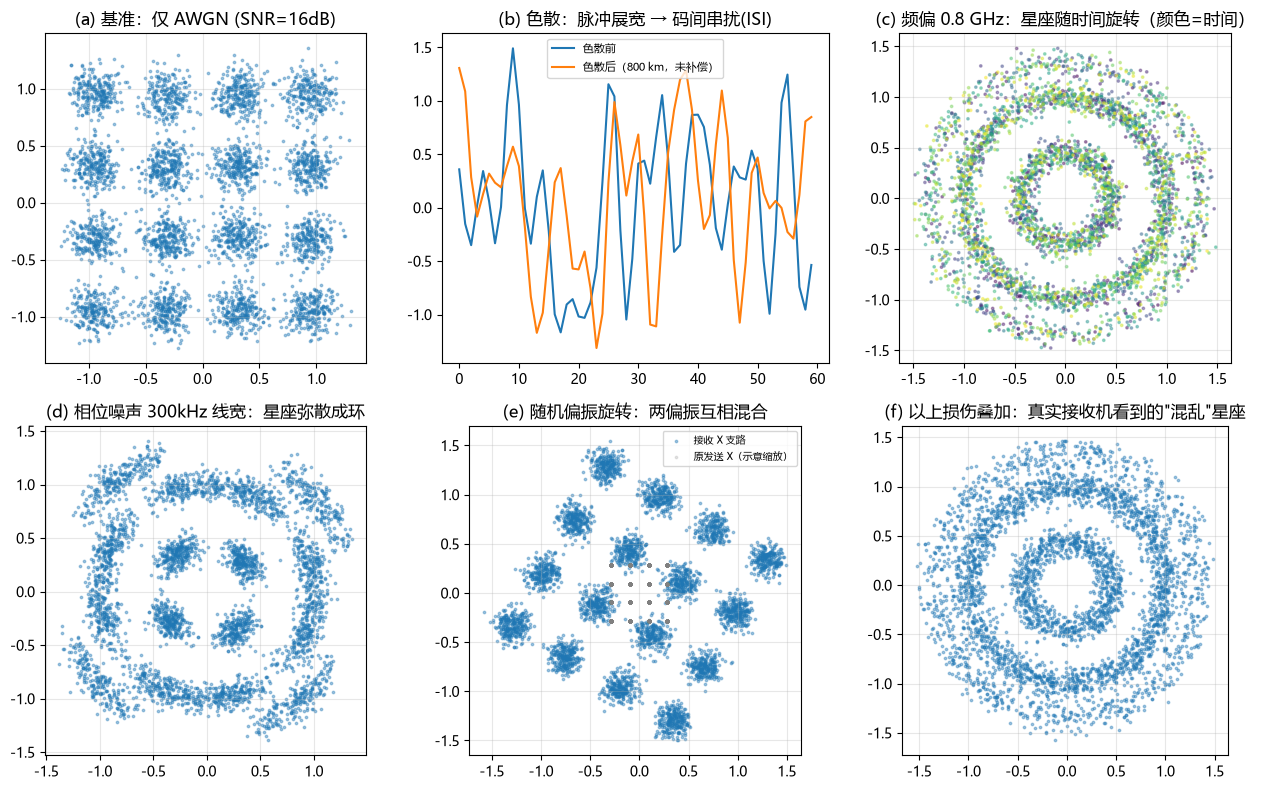

In [6]:
rs = 32e9                                # 符号率 32 GBd
sps2 = 2                                 # 这一部分用 2 sps 即可
N = 4000
c = tx.qam(16)
bits2 = tx.rand_bits((2, N * 4), rng)
s = tx.modulate(bits2, c)                 # 理想发送符号 (2, N)
x = normalize(tx.pulse_shape(s, sps2, 0.1))
fs2 = rs * sps2
mf = lambda v: tx.matched_filter(v, sps2, 0.1)[:, ::sps2]   # 匹配滤波+下采样，方便直接观察符号

fig, ax = plt.subplots(2, 3, figsize=(13, 8))

# (a) 理想基准：只加 AWGN
r0 = awgn(s, 16, rng=rng)
ax[0,0].scatter(r0[0].real, r0[0].imag, s=3, alpha=.4); ax[0,0].set_title('(a) 基准：仅 AWGN (SNR=16dB)')

# (b) 色散（未补偿）：对符号序列本身看不太出"形状"，但时域脉冲被展宽、产生码间串扰(ISI)
y_cd = channel.cd(x, fs2, L=800, D=17.0)          # 800 km 色散，未加噪声，方便看纯色散效应
ax[0,1].plot(np.real(x[0, 200:260]), label='色散前')
ax[0,1].plot(np.real(y_cd[0, 200:260]), label='色散后（800 km，未补偿）')
ax[0,1].set_title('(b) 色散：脉冲展宽 → 码间串扰(ISI)'); ax[0,1].legend(fontsize=8)

# (c) 频偏：星座随时间持续旋转（螺旋状）
r_fo = dsp.fo_comp(awgn(s, 20, rng=rng), -0.8e9, rs)   # 注入 -0.8 GHz 频偏（fo_comp 的负频率=注入正频偏）
ax[0,2].scatter(r_fo[0].real, r_fo[0].imag, s=3, alpha=.4, c=np.arange(N), cmap='viridis')
ax[0,2].set_title('(c) 频偏 0.8 GHz：星座随时间旋转（颜色=时间）')

# (d) 激光相位噪声：星座弥散成"圆弧状"环
pn = dev.laser(N, rs, linewidth=300e3, rng=rng) / np.sqrt(1e-3)
r_pn = awgn(s * pn, 20, rng=rng)
ax[1,0].scatter(r_pn[0].real, r_pn[0].imag, s=3, alpha=.4)
ax[1,0].set_title('(d) 相位噪声 300kHz 线宽：星座弥散成环')

# (e) 偏振随机耦合：X/Y 偏振信号互相"泄漏"混合
U = dev.random_unitary(rng)
r_pol = awgn(U @ s, 20, rng=rng)
ax[1,1].scatter(r_pol[0].real, r_pol[0].imag, s=3, alpha=.4, label='接收 X 支路')
ax[1,1].scatter(s[0].real*0.3, s[0].imag*0.3, s=3, alpha=.2, c='gray', label='原发送 X（示意缩放）')
ax[1,1].set_title('(e) 随机偏振旋转：两偏振互相混合'); ax[1,1].legend(fontsize=7)

# (f) 综合：以上损伤叠加后的"典型接收星座"
r_all = awgn(dsp.fo_comp(U @ (s * pn), -0.8e9, rs), 20, rng=rng)
ax[1,2].scatter(r_all[0].real, r_all[0].imag, s=3, alpha=.4)
ax[1,2].set_title('(f) 以上损伤叠加：真实接收机看到的"混乱"星座')

for a in ax.ravel()[[0,2,3,4,5]]:
    a.set_aspect('equal'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 第三部分：接收端 DSP 逐步演示

针对第二部分展示的各种损伤，本节按文档 §8 的顺序，逐一演示对应算法如何把星座"修"回去。为了聚焦每个算法本身，这里继续使用简化信道（不含完整 SSFM），完整真实链路见第四部分。

### 3.1 色散补偿（CDC, Chromatic Dispersion Compensation）

原理：色散在频域是纯相位滤波器，可用精确的逆滤波器一步补偿（见文档 §8.2）。

真实长度 800 km，盲估计结果 800 km


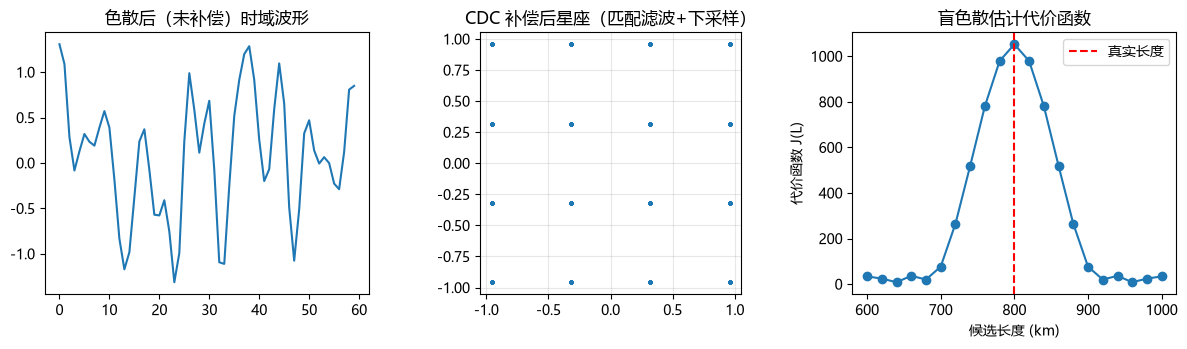

In [7]:
L_true = 800   # km
y = channel.cd(x, fs2, L_true, D=17.0)
y_cdc = dsp.cdc(y, fs2, L_true, D=17.0)       # 已知长度，直接补偿

# 盲色散估计：扫描候选长度，找平方律时钟音最强的位置
L_grid = np.arange(600, 1001, 20)
L_hat, cost = dsp.cd_estimate(y, fs2, rs, L_grid, D=17.0)
print(f'真实长度 {L_true} km，盲估计结果 {L_hat} km')

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
ax[0].plot(np.real(y[0, 200:260])); ax[0].set_title('色散后（未补偿）时域波形')
y_cdc_sym = mf(y_cdc)
ax[1].scatter(y_cdc_sym[0].real[:400], y_cdc_sym[0].imag[:400], s=4)
ax[1].set_aspect('equal'); ax[1].set_title('CDC 补偿后星座（匹配滤波+下采样）'); ax[1].grid(alpha=.3)
ax[2].plot(L_grid, cost, 'o-'); ax[2].axvline(L_true, color='r', ls='--', label='真实长度')
ax[2].set_xlabel('候选长度 (km)'); ax[2].set_ylabel('代价函数 J(L)'); ax[2].legend(); ax[2].set_title('盲色散估计代价函数')
plt.tight_layout(); plt.show()

### 3.2 定时恢复（Timing Recovery）

原理：ADC 采样时刻与符号中心通常不对齐，需要估计分数符号定时偏差。演示 Godard 前馈法（`timing_ff`）与 Gardner 反馈环（`gardner`），见文档 §8.4。

真实偏差 = 0.37 采样点
Godard 前馈估计 = 0.370 采样点
Gardner 反馈收敛值 = 0.379 采样点


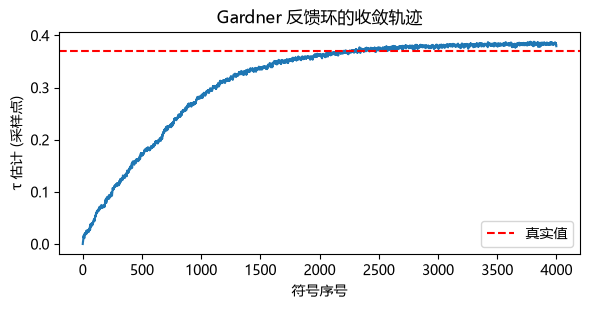

In [8]:
tau_true = 0.37                                # 注入 0.37 个采样点的定时偏差
x_shift = delay(x, tau_true / fs2, fs2)

_, tau_ff = dsp.timing_ff(x_shift, sps2)
y_gard, taus = dsp.gardner(x_shift, mu=2e-3, sps=sps2)

print(f'真实偏差 = {tau_true} 采样点')
print(f'Godard 前馈估计 = {tau_ff:.3f} 采样点')
print(f'Gardner 反馈收敛值 = {taus[-1]:.3f} 采样点')

plt.figure(figsize=(6, 3.2))
plt.plot(taus); plt.axhline(tau_true, color='r', ls='--', label='真实值')
plt.xlabel('符号序号'); plt.ylabel('τ 估计 (采样点)'); plt.title('Gardner 反馈环的收敛轨迹'); plt.legend()
plt.tight_layout(); plt.show()

### 3.3 2×2 MIMO 自适应均衡：偏振解复用

原理：用恒模算法（CMA）先粗收敛、半径判决算法（RDE）再精收敛的两阶段蝶形 FIR 均衡器，同时完成偏振解复用与残余线性损伤补偿，见文档 §8.5。

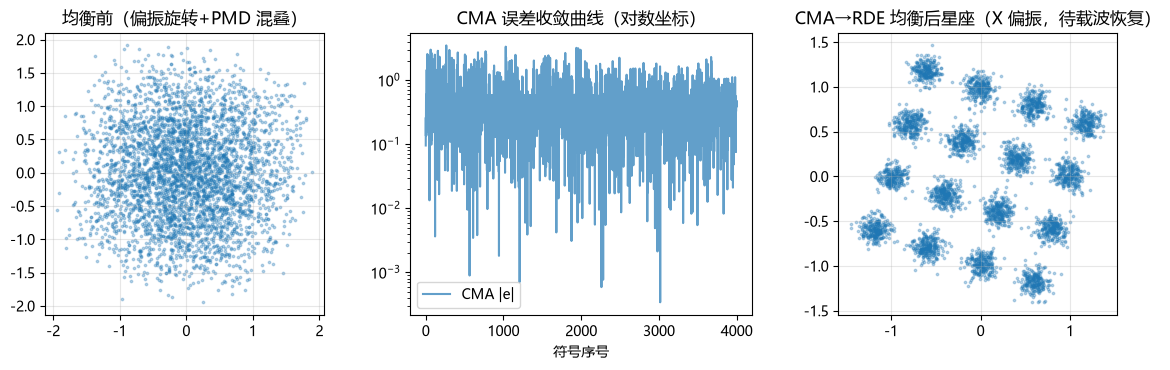

提示：此时星座仍是"旋转的圆环"——因为还没做频偏/相位恢复，这是正常现象，继续往下看。


In [9]:
# 注入随机偏振旋转 + 固定 DGD（差分群时延，一阶 PMD）
x_pol = awgn(dev.dgd(dev.random_unitary(rng) @ x, fs2, tau=8e-12), 22, sps2, rng)

_, w_cma, err_cma = dsp.mimo_eq(x_pol, ntaps=15, mu=1e-3, sps=sps2, mode='cma', const=c)
y_rde, w_rde, err_rde = dsp.mimo_eq(x_pol, ntaps=15, mu=5e-4, sps=sps2, mode='rde', const=c, w=w_cma)

fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
ax[0].scatter(x_pol[0, ::sps2].real, x_pol[0, ::sps2].imag, s=3, alpha=.3)
ax[0].set_title('均衡前（偏振旋转+PMD 混叠）'); ax[0].set_aspect('equal')
ax[1].plot(err_cma[0], alpha=.7, label='CMA |e|'); ax[1].set_yscale('log')
ax[1].set_xlabel('符号序号'); ax[1].set_title('CMA 误差收敛曲线（对数坐标）'); ax[1].legend()
ax[2].scatter(y_rde[0].real, y_rde[0].imag, s=3, alpha=.3)
ax[2].set_title('CMA→RDE 均衡后星座（X 偏振，待载波恢复）'); ax[2].set_aspect('equal')
for a in (ax[0], ax[2]): a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print('提示：此时星座仍是"旋转的圆环"——因为还没做频偏/相位恢复，这是正常现象，继续往下看。')

### 3.4 频偏估计与补偿（FOE, Frequency Offset Estimation）

原理：对符号做 M 次方（这里 M=4）消除 QAM 的相位模糊，在频谱上暴露出与频偏对应的单频分量，见文档 §8.6。

真实频偏 = -1.200 GHz，FFT 谱峰法估计 = 1.200 GHz


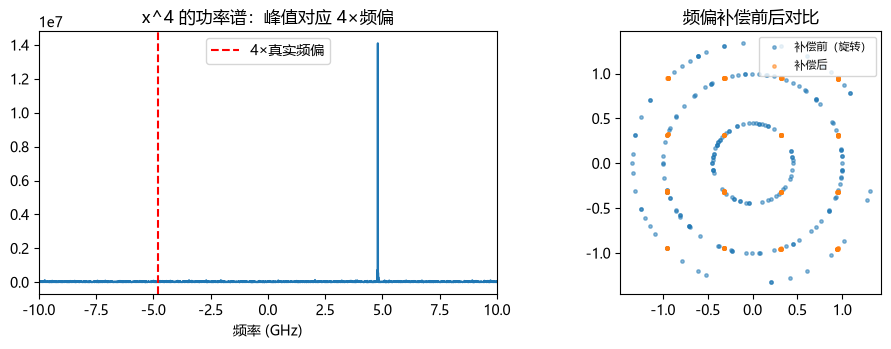

In [10]:
f_true = -1.2e9
xf = dsp.fo_comp(s, f_true, rs)        # 注入频偏（符号级，便于演示 FFT 谱峰）

nfft = 4 * 2**int(np.ceil(np.log2(xf.shape[-1])))
spec = np.sum(np.abs(np.fft.fft(xf**4, nfft, axis=-1))**2, 0)
faxis = np.fft.fftshift(np.fft.fftfreq(nfft, 1/rs))

f_hat = dsp.foe(xf, rs, method='fft')
print(f'真实频偏 = {f_true/1e9:.3f} GHz，FFT 谱峰法估计 = {f_hat/1e9:.3f} GHz')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(faxis/1e9, np.fft.fftshift(spec)); ax[0].axvline(4*f_true/1e9, color='r', ls='--', label='4×真实频偏')
ax[0].set_xlim(-10, 10); ax[0].set_xlabel('频率 (GHz)'); ax[0].set_title('x^4 的功率谱：峰值对应 4×频偏'); ax[0].legend()
y_fo = dsp.fo_comp(xf, f_hat, rs)
ax[1].scatter(xf[0,:200].real, xf[0,:200].imag, s=6, alpha=.5, label='补偿前（旋转）')
ax[1].scatter(y_fo[0,:200].real, y_fo[0,:200].imag, s=6, alpha=.5, label='补偿后')
ax[1].set_aspect('equal'); ax[1].legend(fontsize=8); ax[1].set_title('频偏补偿前后对比')
plt.tight_layout(); plt.show()

### 3.5 载波相位恢复（CPR, Carrier Phase Recovery）

对比盲相位搜索 BPS（Blind Phase Search）与 Viterbi-Viterbi（VV）两种算法，见文档 §8.7。两者都存在固有的相位模糊（BPS 为 π/2，VV 为 2π/4），需要配合第 3.6 节的模糊消除。

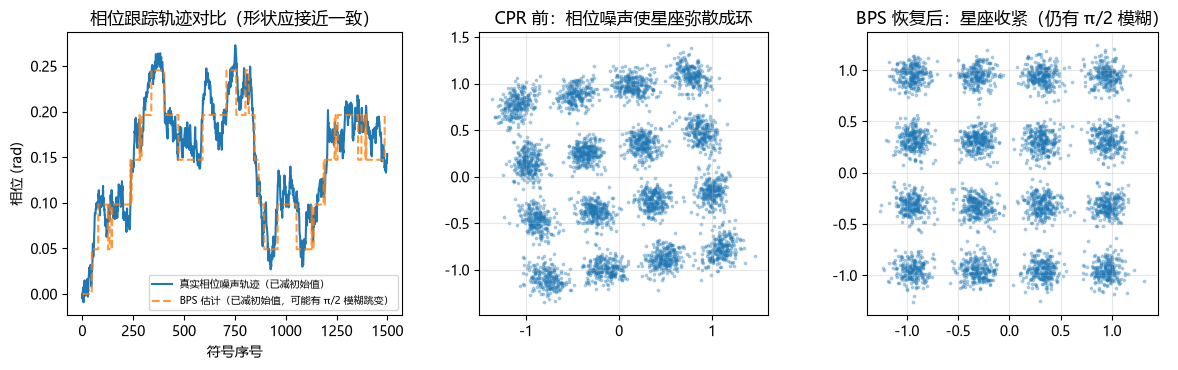

消除模糊后的有效 SNR：BPS = 17.93 dB，VV = 17.50 dB（AWGN 设定值 18 dB）


In [11]:
pn2 = dev.laser(N, rs, linewidth=200e3, rng=rng) / np.sqrt(1e-3)
r_pn2 = awgn(s * pn2, 18, rng=rng)

y_bps, phi_bps = dsp.bps(r_pn2, c, n_test=32, n=64)
y_vv, phi_vv = dsp.vv(r_pn2, n=64, m=4, const=c)

true_phase = np.unwrap(np.angle(pn2))

phi_bps_u = np.unwrap(phi_bps[0, :1500])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
ax[0].plot(true_phase[:1500] - true_phase[0], label='真实相位噪声轨迹（已减初始值）')
ax[0].plot(phi_bps_u - phi_bps_u[0], '--', label='BPS 估计（已减初始值，可能有 π/2 模糊跳变）', alpha=.8)
ax[0].set_xlabel('符号序号'); ax[0].set_ylabel('相位 (rad)'); ax[0].legend(fontsize=7); ax[0].set_title('相位跟踪轨迹对比（形状应接近一致）')
ax[1].scatter(r_pn2[0].real, r_pn2[0].imag, s=3, alpha=.3); ax[1].set_title('CPR 前：相位噪声使星座弥散成环'); ax[1].set_aspect('equal')
ax[2].scatter(y_bps[0].real, y_bps[0].imag, s=3, alpha=.3); ax[2].set_title('BPS 恢复后：星座收紧（仍有 π/2 模糊）'); ax[2].set_aspect('equal')
for a in (ax[1], ax[2]): a.grid(alpha=.3)
plt.tight_layout(); plt.show()

snr_bps = metrics.snr(dsp.fix_ambiguity(y_bps, s), s)
snr_vv = metrics.snr(dsp.fix_ambiguity(y_vv, s), s)
print(f'消除模糊后的有效 SNR：BPS = {snr_bps:.2f} dB，VV = {snr_vv:.2f} dB（AWGN 设定值 18 dB）')

### 3.6 相位模糊与周跳消除（Ambiguity / Cycle-Slip Resolution）

原理：用已知的训练/导频符号估计并消除 π/2 整数倍的相位模糊；低 OSNR 下还可能发生**周跳**（相位估计在跟踪中突然跳变），用分段（滑动平均）判定可以把误差限制在局部，见文档 §8.9。

In [12]:
mask = np.zeros(N, bool); mask[::32] = True     # 假设每 32 个符号中有 1 个已知（相当于导频）

# 对比：全局估计一次 vs 分段估计（能抵抗局部周跳）
y_global = dsp.fix_ambiguity(y_bps, s, mask, n=None)
y_segment = dsp.fix_ambiguity(y_bps, s, mask, n=5)
print('两种方式在这个干净例子里结果应当一致（没有真实周跳时）：')
print(f'  全局：SNR = {metrics.snr(y_global, s):.2f} dB')
print(f'  分段：SNR = {metrics.snr(y_segment, s):.2f} dB')
print('实际低 OSNR 场景中，分段方式能避免个别周跳污染全部符号的旋转估计（参见文档 §8.9 与 README FAQ）。')

两种方式在这个干净例子里结果应当一致（没有真实周跳时）：
  全局：SNR = 17.93 dB
  分段：SNR = 17.93 dB
实际低 OSNR 场景中，分段方式能避免个别周跳污染全部符号的旋转估计（参见文档 §8.9 与 README FAQ）。


## 第四部分：完整系统仿真（真实光纤链路 + 全部器件）

现在把第一到第三部分的每个模块按文档 §1 的顺序串联起来，并把"理想信道+单项损伤"换成**真实的多跨光纤链路**（10×80 km，SSMF，对称分步傅里叶法求解 Manakov 方程，自动包含自相位调制 SPM）。器件也换成更完整的模型（DAC/ADC 量化、激光器相位噪声、IQ 调制器误差、EDFA+ASE、偏振相关损耗 PDL、WSS 滤波等）。

最后用封装好的 `system.rx_dsp`（内部就是前面手动调用的那些函数）一键跑一遍接收 DSP 链，验证与手动演示的原理一致。

In [13]:
from optsim.system import Config, tx_signal, rx_dsp

cfg = Config(M=16, rs=32e9, sps=4, n_blocks=300, band='C', fiber='SSMF',
             n_spans=10, L=80, p_launch=1.0, fib_kw={'pmd': 0.1},
             nl_comp='cdc', cpr='bps', seed=3)
fib, fs = cfg.fib, cfg.fs
print(f'C 波段 SSMF 参数：α={fib["alpha"]:.3f} dB/km, D={fib["D"]:.2f} ps/(nm·km), '
      f'γ={fib["gamma"]:.3f} 1/(W·km), 放大器={fib["amplifier"]}, NF={fib["nf"]} dB')

# ---- 发射端：Tx DSP + 全部光电器件 ----
ref = tx_signal(cfg)
u = 0.2 * dev.dac(ref['wave'], fs, enob=6, bw=0.7*cfg.rs)
E = dev.dp_iq_mod(dev.laser(u.shape[1], fs, 16, 100e3, rng=rng), u, phase_err=np.deg2rad(1))
E = dev.edfa(E, fs, p_out_dbm=cfg.p_launch, nf_db=fib['nf'], f0=fib['f0'], rng=rng)
E_tx = E.copy()
print(f'发射光场形状 {E.shape}，总功率 = {10*np.log10(np.sum(np.mean(np.abs(E)**2,1))/1e-3):.2f} dBm')

C 波段 SSMF 参数：α=0.200 dB/km, D=16.97 ps/(nm·km), γ=1.317 1/(W·km), 放大器=C-EDFA, NF=5.0 dB
发射光场形状 (2, 46592)，总功率 = 1.00 dBm


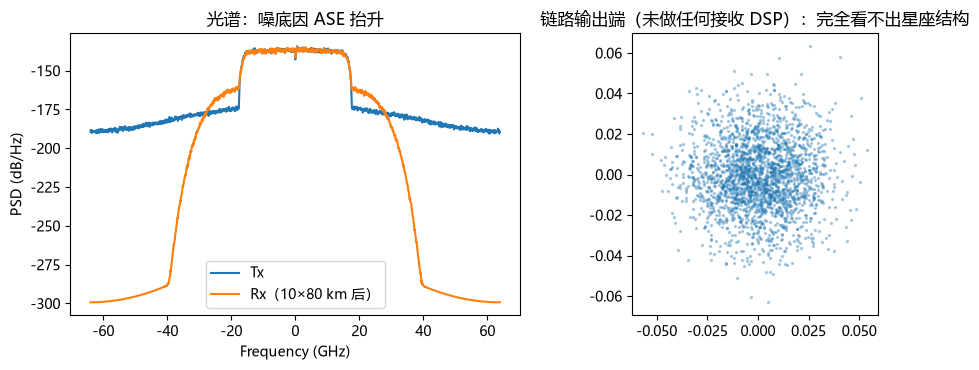

In [14]:
# ---- 光纤链路：10×80 km SSMF，SSFM 求解 Manakov 方程（自动含 SPM）----
E = channel.link(E, fs, fib, cfg.n_spans, phi_max=cfg.phi_max, rng=rng)
E = dev.pdl(E, 0.5, theta=0.3)
E = dev.optical_filter(E, fs, bw=1.2*cfg.rs*(1+cfg.beta), order=3)   # WSS

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
plots.spectrum(E_tx, fs, ax[0], 'Tx'); plots.spectrum(E, fs, ax[0], f'Rx（{cfg.n_spans}×{fib["L"]:.0f} km 后）')
ax[0].legend(); ax[0].set_title('光谱：噪底因 ASE 抬升')
ax[1].scatter(E[0, ::20].real, E[0, ::20].imag, s=2, alpha=.3)
ax[1].set_title('链路输出端（未做任何接收 DSP）：完全看不出星座结构'); ax[1].set_aspect('equal')
plt.tight_layout(); plt.show()

In [15]:
# ---- 相干接收机 + ADC ----
lo = dev.laser(E.shape[1], fs, p_dbm=13, linewidth=100e3, f_offset=1.5e9, rng=rng)
skew = [0, 1.5e-12, 0, -1e-12]
r = dev.coherent_rx(E, lo, fs, skew=skew, R=0.8, bw=0.75*cfg.rs, T=300, rng=rng)
r = dev.adc(r, fs, cfg.fs_adc, enob=6, bw=0.75*cfg.rs)
r = dsp.deskew(r, cfg.fs_adc, skew)
print(f'ADC 输出 {r.shape}，采样率 {cfg.fs_adc/1e9:.0f} GSa/s')

ADC 输出 (2, 36400)，采样率 100 GSa/s


频偏估计 = -1.500 GHz（本振注入 +1.5 GHz，相干探测后符号呈现相反符号的频偏，与约定一致）
帧同步偏移 lag = 11643
BER = 8.065e-05（X: 5.376e-05, Y: 1.075e-04）
SNR = 18.31 dB，EVM = 12.1%，GMI = 3.998 bit/symbol/pol


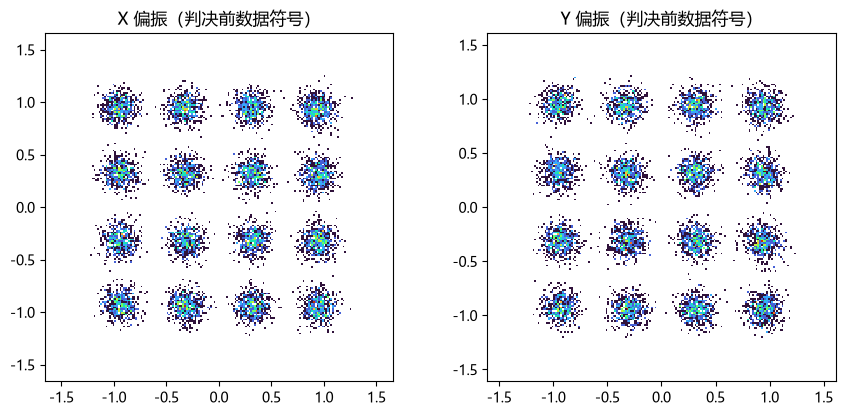

In [16]:
# ---- 一键接收 DSP 链（内部顺序与第三部分手动演示完全一致，见 system.py 源码）----
res = rx_dsp(r, cfg, ref)
print(f"频偏估计 = {res['fo']/1e9:.3f} GHz（本振注入 +1.5 GHz，相干探测后符号呈现相反符号的频偏，与约定一致）")
print(f"帧同步偏移 lag = {res['lag']}")
print(f"BER = {res['ber']:.3e}（X: {res['ber_xy'][0]:.3e}, Y: {res['ber_xy'][1]:.3e}）")
print(f"SNR = {res['snr']:.2f} dB，EVM = {res['evm']:.1f}%，GMI = {res['gmi']:.3f} bit/symbol/pol")

fig, ax = plt.subplots(1, 2, figsize=(9, 4.2))
plots.constellation(res['sym'][0], ax[0], 'X 偏振（判决前数据符号）')
plots.constellation(res['sym'][1], ax[1], 'Y 偏振（判决前数据符号）')
plt.tight_layout(); plt.show()

## 第五部分：拓展实验 —— 背靠背（B2B）BER-OSNR 曲线

对比仿真（含激光相位噪声、频偏、完整接收 DSP 链）与 AWGN 信道下的理论 BER（文档 §10），验证整条 DSP 链路的**实现代价**（implementation penalty）处于合理范围（通常 <1 dB）。

In [17]:
cfg_b2b = Config(M=16, rs=32e9, sps=4, n_blocks=200, n_spans=0, fs_adc=128e9, seed=5)
ref_b2b = tx_signal(cfg_b2b)
Nb = ref_b2b['wave'].shape[1]

osnr_list = np.arange(15, 23, 1.0)
ber_list = []
for o in osnr_list:
    E = ref_b2b['wave'] * dev.laser(Nb, cfg_b2b.fs, 0, 100e3, rng=rng)
    E = dev.set_osnr(E, o, cfg_b2b.fs, rng=rng)
    lo = dev.laser(Nb, cfg_b2b.fs, 10, 100e3, f_offset=0.8e9, rng=rng)
    r_b2b = dev.coherent_rx(E, lo, cfg_b2b.fs, shot=False, rng=rng)
    out = rx_dsp(r_b2b, cfg_b2b, ref_b2b)
    ber_list.append(out['ber'])
    print(f'OSNR {o:4.1f} dB -> BER {out["ber"]:.3e}  (SNR {out["snr"]:.2f} dB)')

OSNR 15.0 dB -> BER 5.448e-02  (SNR 10.37 dB)


OSNR 16.0 dB -> BER 3.720e-02  (SNR 11.46 dB)


OSNR 17.0 dB -> BER 2.377e-02  (SNR 12.42 dB)


OSNR 18.0 dB -> BER 1.202e-02  (SNR 13.65 dB)


OSNR 19.0 dB -> BER 7.460e-03  (SNR 14.51 dB)


OSNR 20.0 dB -> BER 2.923e-03  (SNR 15.55 dB)


OSNR 21.0 dB -> BER 9.879e-04  (SNR 16.59 dB)


OSNR 22.0 dB -> BER 3.427e-04  (SNR 17.56 dB)


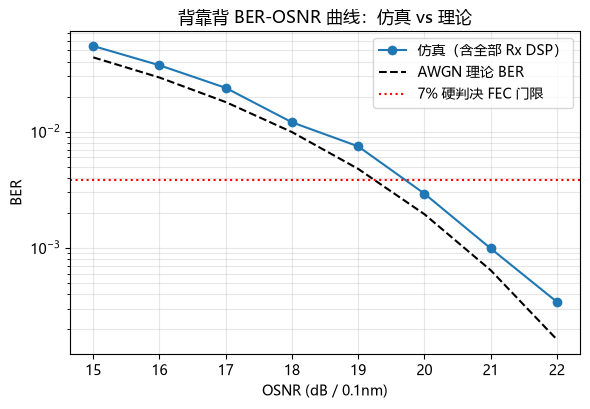

In [18]:
snr_th = metrics.osnr2snr(osnr_list, cfg_b2b.rs)
ber_th = metrics.ber_theory(cfg_b2b.M, snr_th)

plt.figure(figsize=(6, 4.2))
plt.semilogy(osnr_list, np.maximum(ber_list, 1e-6), 'o-', label='仿真（含全部 Rx DSP）')
plt.semilogy(osnr_list, ber_th, 'k--', label='AWGN 理论 BER')
plt.axhline(metrics.HD_FEC, color='r', ls=':', label='7% 硬判决 FEC 门限')
plt.xlabel('OSNR (dB / 0.1nm)'); plt.ylabel('BER'); plt.grid(True, which='both', alpha=.3)
plt.legend(); plt.title('背靠背 BER-OSNR 曲线：仿真 vs 理论')
plt.tight_layout(); plt.show()

## 第六部分：总结与延伸阅读

本 Notebook 完整走了一遍相干 DP-16QAM 系统的仿真链路：

1. **发射端**：比特 → Gray QAM 映射 → 成帧（训练+导频）→ RRC 脉冲成形；
2. **信道损伤的"指纹"**：色散造成码间串扰、频偏造成星座旋转、相位噪声造成星座弥散成环、偏振耦合造成两偏振混叠——这决定了接收 DSP 链每一步要解决的具体问题；
3. **接收 DSP 链**：色散补偿（CDC）→ 定时恢复 → 2×2 MIMO 均衡（CMA→RDE，偏振解复用）→ 频偏估计补偿 → 载波相位恢复（BPS/VV）→ 模糊/周跳消除，每一步都针对第 2 步中的某种损伤；
4. **完整系统**：把以上模块嵌入真实的多跨光纤链路（分步傅里叶法求解 Manakov 方程，自动包含自相位调制等 Kerr 非线性）与全部收发机器件模型，用封装好的 `system.rx_dsp` 一键运行，并与手动演示的结果互相印证；
5. **性能评估**：BER-OSNR 曲线与理论对比，确认 DSP 链路的实现代价在合理范围。

### 下一步可以探索

- `Python/examples/wdm_system.py`：波分复用（WDM）系统，光纤非线性的交叉相位调制（XPM）、四波混频（FWM）如何在信道间产生相互作用；
- `Python/examples/launch_power_sweep.py`：入纤功率扫描，直观看到"功率太低噪声主导、功率太高非线性主导"的最优功率现象，并与高斯噪声（GN）解析模型对比；
- `Python/examples/band_gn_analysis.py`：O/E/S/C/L/U 不同波段、不同光纤类型的容量极限分析；
- `Python/examples/imdd_pam4.py`：强度调制直接检测（IM-DD）PAM4 系统；
- `Python/examples/phi_otdr_das.py`：φ-OTDR 分布式声波传感（光纤传感而非通信的应用）；
- `docs/仿真原理与DSP算法详解.md`：本 Notebook 对应的完整文字版原理文档，包含全部公式推导与参考文献。

### 关键术语中英对照速查

| 中文 | 英文 | 中文 | 英文 |
|---|---|---|---|
| 正交幅度调制 | QAM (Quadrature Amplitude Modulation) | 偏振复用 | PDM (Polarization-Division Multiplexing) |
| 根升余弦 | RRC (Root-Raised-Cosine) | 码间串扰 | ISI (Inter-Symbol Interference) |
| 群速度色散 | GVD (Group Velocity Dispersion) | 自相位调制 | SPM (Self-Phase Modulation) |
| 交叉相位调制 | XPM (Cross-Phase Modulation) | 四波混频 | FWM (Four-Wave Mixing) |
| 受激拉曼散射 | SRS (Stimulated Raman Scattering) | 偏振模色散 | PMD (Polarization Mode Dispersion) |
| 分步傅里叶法 | SSFM (Split-Step Fourier Method) | 放大自发辐射 | ASE (Amplified Spontaneous Emission) |
| 数字反向传播 | DBP (Digital Backpropagation) | 恒模算法 | CMA (Constant Modulus Algorithm) |
| 半径判决均衡 | RDE (Radius-Directed Equalizer) | 频偏估计 | FOE (Frequency Offset Estimation) |
| 载波相位恢复 | CPR (Carrier Phase Recovery) | 盲相位搜索 | BPS (Blind Phase Search) |
| 判决引导锁相环 | DD-PLL (Decision-Directed PLL) | 误码率 | BER (Bit Error Rate) |
| 误差矢量幅度 | EVM (Error Vector Magnitude) | 广义互信息 | GMI (Generalized Mutual Information) |
| 光信噪比 | OSNR (Optical Signal-to-Noise Ratio) | 高斯噪声模型 | GN model (Gaussian Noise model) |

---

## 附录 A：典型器件与仪器参数参考

下表给出相干光通信系统中常见器件的**典型工程参数范围**（综合自公开文献与行业常见商用器件的数量级，非某一具体厂商型号的精确规格，实际项目请以器件数据手册为准），供设置仿真参数时做数量级参考、或与实验室仪器参数对照。

In [19]:
import pandas as pd  # 仅用于表格展示，不影响仿真逻辑
specs = {
    '器件': ['窄线宽激光器（ECL/ITLA）', '相干接收用本振激光器', 'DAC（任意波形发生器 AWG 级）',
            'ADC（示波器/相干接收 DSP 级）', 'IQ 调制器（LiNbO3/InP）', 'EDFA（C 波段功率放大）',
            'PIN/APD 光电探测器', '相干接收机整体灵敏度'],
    '关键参数': ['线宽 Δν', '线宽 Δν，RIN', 'ENOB，采样率，模拟带宽', 'ENOB，采样率，模拟带宽',
                '半波电压 Vπ，插损，消光比', '增益，噪声系数 NF，饱和输出功率', '响应度 R，暗电流，3dB 带宽',
                '达到 FEC 门限所需 OSNR（0.1nm）'],
    '典型范围': ['10 kHz ~ 1 MHz（窄线宽 <100 kHz 用于高阶 QAM/长距离）', '同上，RIN 典型 < -150 dB/Hz',
                '6~8 bit，64~120 GSa/s，30~40 GHz', '5.5~8 bit，80~256 GSa/s，30~40 GHz',
                '2~6 V，2~4 dB，>20 dB', '15~25 dB，4~6 dB，13~23 dBm',
                '0.6~0.9 A/W，<10 nA，>30 GHz', 'DP-16QAM 典型 18~20 dB，DP-64QAM 典型 24~27 dB（@7%HD-FEC 门限附近）'],
}
pd.DataFrame(specs)

,器件,关键参数,典型范围
0,窄线宽激光器（ECL/ITLA）,线宽 Δν,10 kHz ~ 1 MHz（窄线宽 <100 kHz 用于高阶 QAM/长距离）
1,相干接收用本振激光器,线宽 Δν，RIN,同上，RIN 典型 < -150 dB/Hz
2,DAC（任意波形发生器 AWG 级）,ENOB，采样率，模拟带宽,6~8 bit，64~120 GSa/s，30~40 GHz
3,ADC（示波器/相干接收 DSP 级）,ENOB，采样率，模拟带宽,5.5~8 bit，80~256 GSa/s，30~40 GHz
4,IQ 调制器（LiNbO3/InP）,半波电压 Vπ，插损，消光比,2~6 V，2~4 dB，>20 dB
5,EDFA（C 波段功率放大）,增益，噪声系数 NF，饱和输出功率,15~25 dB，4~6 dB，13~23 dBm
6,PIN/APD 光电探测器,响应度 R，暗电流，3dB 带宽,0.6~0.9 A/W，<10 nA，>30 GHz
7,相干接收机整体灵敏度,达到 FEC 门限所需 OSNR（0.1nm）,DP-16QAM 典型 18~20 dB，DP-64QAM 典型 24~27 dB（@7%H...


> **如何把这些参数接到本仓库的仿真里**：`devices.laser(..., linewidth=100e3)` 对应线宽；`devices.dac/adc(..., enob=6, bw=30e9)` 对应 DAC/ADC；`devices.iq_mod(..., vpi=2.5)` 对应调制器半波电压；`devices.edfa(..., nf_db=5.0)` 对应放大器噪声系数。把实验室实际仪器的数据手册参数代入这些函数，就能让仿真更贴近具体实验条件。

## 附录 B：结果解读指南 —— 星座图"诊断图鉴"

星座图的**形状**本身就是诊断信息：不同损伤会在星座上留下特征性的"指纹"。下面用仿真人为注入 8 种常见损伤（且只注入这一种，便于识别"纯净"的特征），做成一张对照图鉴。实际调试时，接收星座往往是多种损伤叠加，需要先怀疑影响最大的一两种、逐步排查。

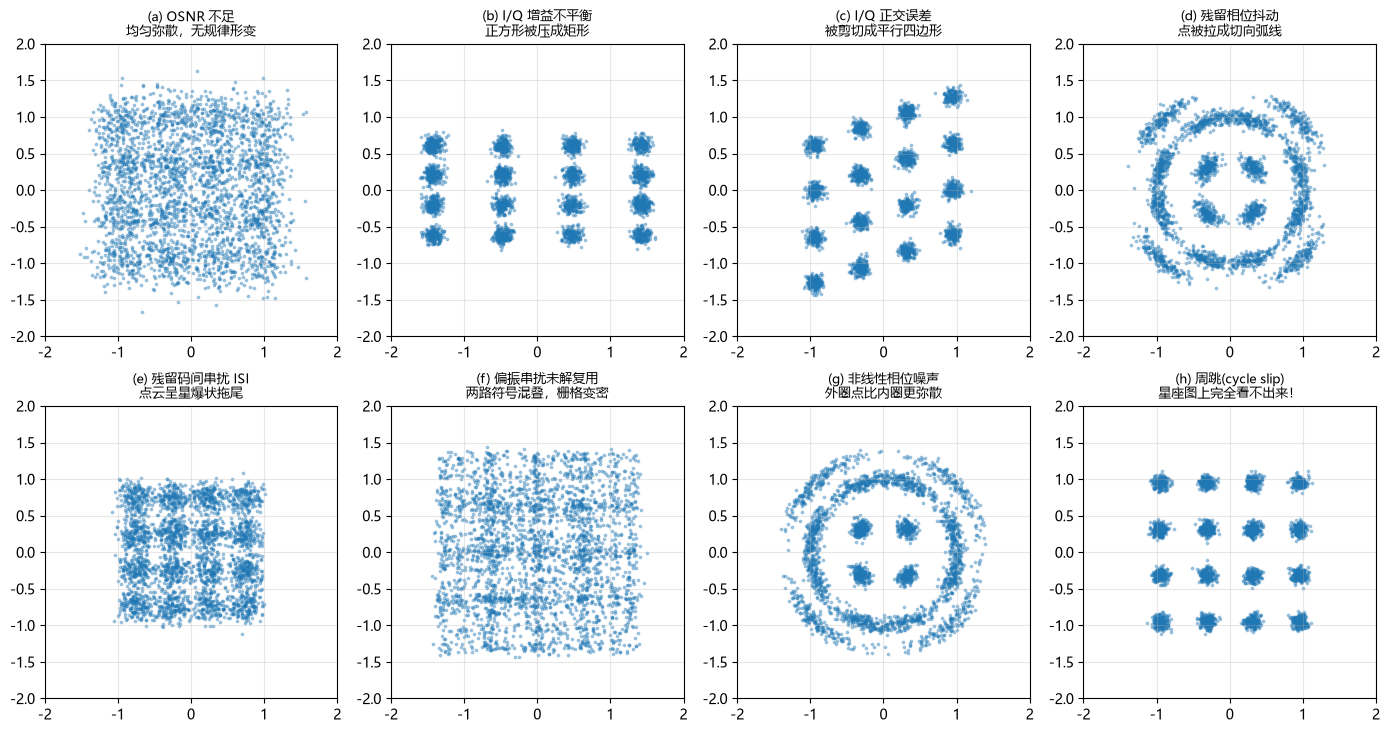

注意：(d)(e)(g)(h) 为简化示意，用于直观展示特征形状，并非对应物理损伤的严格统计模型；
真实诊断仍需结合第三部分演示的具体算法（如 dsp.cd_estimate、dsp.foe 的输出）定量确认。

(h) 的关键教训：方形 QAM 本身对 90° 旋转具有 4 重对称性，整体旋转 90° 后的星座点集与旋转前
完全重合——所以周跳在"接收星座散点图"上永远看不出任何异常！它只能通过与已知参考符号
（训练/导频）逐个比对发现：旋转发生的那一刻之后，所有判决都会相对真值错位。这正是
为什么必须用 dsp.fix_ambiguity 这类"数据辅助"方法，而不能指望"看星座图"来发现周跳。

量化验证：直接判决误符号率 = 0.500（后半数据几乎全错）；
      分段 fix_ambiguity 修复后误符号率 = 0.0000（接近 0，证明确有周跳但已被修复）


In [20]:
Nd = 3000
cc = tx.qam(16)
sd = tx.modulate(tx.rand_bits((2, Nd*4), rng), cc)   # 干净的发送符号 (2, Nd)
sY = tx.modulate(tx.rand_bits((2, Nd*4), rng), cc)    # 另一路独立符号，用于模拟偏振串扰

cases = {}
cases['(a) OSNR 不足\n均匀弥散，无规律形变'] = awgn(sd, 11, rng=rng)
cases['(b) I/Q 增益不平衡\n正方形被压成矩形'] = awgn(sd.real*1.5 + 1j*sd.imag*0.65, 22, rng=rng)
cases['(c) I/Q 正交误差\n被剪切成平行四边形'] = awgn(sd.real + 1j*(sd.imag + 0.35*sd.real), 22, rng=rng)
cases['(d) 残留相位抖动\n点被拉成切向弧线'] = awgn(sd*np.exp(1j*0.18*rng.standard_normal(Nd)), 22, rng=rng)
h_isi = np.array([0.12, 1.0, 0.15])                      # 简化的符号间串扰(ISI)核
cases['(e) 残留码间串扰 ISI\n点云呈星爆状拖尾'] = awgn(np.apply_along_axis(
    lambda v: np.convolve(v, h_isi, 'same')/np.sum(h_isi), 1, sd), 22, rng=rng)
cases['(f) 偏振串扰未解复用\n两路符号混叠，栅格变密'] = awgn(sd + 0.35*sY, 22, rng=rng)
cases['(g) 非线性相位噪声\n外圈点比内圈更弥散'] = awgn(sd*np.exp(1j*0.22*np.abs(sd)*rng.standard_normal(Nd)), 22, rng=rng)
y_slip = np.concatenate([sd[:, :Nd//2], sd[:, Nd//2:]*1j], axis=1)   # 后半数据整体旋转 90°（模拟一次周跳）
cases['(h) 周跳(cycle slip)\n星座图上完全看不出来！'] = awgn(y_slip, 22, rng=rng)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.4))
for ax, (title, y) in zip(axes.ravel(), cases.items()):
    ax.scatter(y[0].real, y[0].imag, s=3, alpha=.35)
    ax.set_title(title, fontsize=9); ax.set_aspect('equal'); ax.grid(alpha=.3)
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2)
plt.tight_layout(); plt.show()

print('注意：(d)(e)(g)(h) 为简化示意，用于直观展示特征形状，并非对应物理损伤的严格统计模型；')
print('真实诊断仍需结合第三部分演示的具体算法（如 dsp.cd_estimate、dsp.foe 的输出）定量确认。\n')
print('(h) 的关键教训：方形 QAM 本身对 90° 旋转具有 4 重对称性，整体旋转 90° 后的星座点集与旋转前')
print('完全重合——所以周跳在"接收星座散点图"上永远看不出任何异常！它只能通过与已知参考符号')
print('（训练/导频）逐个比对发现：旋转发生的那一刻之后，所有判决都会相对真值错位。这正是')
print('为什么必须用 dsp.fix_ambiguity 这类"数据辅助"方法，而不能指望"看星座图"来发现周跳。')
err_before = np.mean(tx.decide(y_slip, cc) != tx.decide(sd, cc))        # 直接判决：后半全错
y_fixed = dsp.fix_ambiguity(y_slip, sd, n=5)                             # 分段模糊消除后修复
err_after = np.mean(tx.decide(y_fixed, cc) != tx.decide(sd, cc))
print(f'\n量化验证：直接判决误符号率 = {err_before:.3f}（后半数据几乎全错）；')
print(f'      分段 fix_ambiguity 修复后误符号率 = {err_after:.4f}（接近 0，证明确有周跳但已被修复）')

**各项指标怎么看**（配合第 10 节/文档 §10）：

| 现象 | 可能原因 | 诊断方法 |
|---|---|---|
| BER 远差于同 SNR 下的理论曲线 | 实现代价过大：ENOB 不足、驱动摆幅使调制器非线性削波、带宽不足引入 ISI、均衡器抽头数不够 | 对照本 Notebook 第五部分的 BER-OSNR 曲线，先确认"干净仿真"（无额外损伤）本身的代价有多大 |
| SNR 正常但 GMI 明显低于 $\log_2 M$ | 可能是噪声非高斯（如残留非线性相位噪声，GMI 公式假设高斯信道会有偏差），也可能是先验非均匀（PCS 场景，这是**正常**现象） | 检查是否使用了 `tx.pcs_symbols`；若未使用但 GMI 偏低，排查 SNR 估计是否准确（`metrics.snr` 已做最小二乘增益校正，仍需确认判决符号是否正确） |
| EVM 和 SNR 换算对不上理论关系 $\mathrm{SNR[dB]}\approx-20\lg(\mathrm{EVM})$ | 多为正常——该近似假设噪声远小于信号且星座各点贡献相近，高阶 QAM 或 PCS 下会有数 dB 偏差 | 两者都报告，不要只看一个 |
| 均衡器输出星座是一堆旋转的同心圆环 | **这是正常现象**，不是 bug——均衡/偏振解复用完成但载波相位/频偏还没补偿（见第 3.3 节末尾的提示） | 继续做 FOE+CPR |

## 附录 C：常见问题排查（Troubleshooting）

以下问题多数是本项目开发过程中实际遇到并修复过的（部分细节见 `README.md` §10 FAQ），或是相干光通信仿真/实验中的通用易错点。

**Q1：CMA/RDE 均衡器不收敛，输出近似随机噪声**
- 可能原因：步长 `mu` 过大导致发散；输入信号未做功率归一化（`mimo_eq` 的误差项依赖星座的 $R_2$，输入功率量级不对会直接发散）；抽头数 `ntaps` 覆盖不了实际的 PMD/残余色散展宽。
- 解决：先用 `normalize()` 归一化输入功率；减小 `mu`（例如 CMA 从 1e-3 降到 1e-4 试试）；适当增大 `ntaps`；确认是否先用 CMA 预收敛过（直接跑 RDE 容易在未收敛的星座上误判决而发散，见第 3.3 节的两阶段策略）。

**Q2：载波相位恢复后星座仍有"螺旋拖尾"或周期性"抖动条纹"**
- 可能原因：发生了**周跳**（cycle slip）——低 OSNR 或线宽过大时，BPS/VV 的相位估计可能在跟踪中突然跳变 π/2 的整数倍；或 CPR 的滑动窗口 `n` 与激光线宽不匹配（窗口太短→跟不住噪声太敏感，太长→跟不上真实相位变化）。
- 解决：优先用导频辅助 `dsp.pilot_cpr`（无相位模糊，更鲁棒）；或用 `dsp.fix_ambiguity(..., n=5)` 分段消除模糊而非全局一次性估计（见第 3.6 节、文档 §8.9、README §10 FAQ）；减小激光线宽或提高导频密度。

**Q3：频偏估计（FOE）结果明显错误、与真实值差一个固定量**
- 可能原因：M 次方 FFT 法的无模糊估计范围是 $\pm f_s/(2M)$（$M=4$ 时为 $\pm R_s/8$），真实频偏超出此范围会被"折叠"估计错误；`nfft` 太小导致频率分辨率不够。
- 解决：确认频偏数量级是否超出估计范围（典型激光器自由运转频偏可达 ±1~2 GHz，而 32 GBd 的 $\pm R_s/8\approx\pm4$ GHz，通常够用，但要留意窄带系统）；增大 `nfft`（代码里默认已补零 4 倍）；必要时先用差分法粗估计再细调。

**Q4：盲色散估计（`cd_estimate`）结果偏离真实长度很多**
- 可能原因：扫描范围 `L_grid` 没覆盖真实值；OSNR 太低或非线性太强，破坏了作为代价函数依据的符号率时钟音。
- 解决：先用链路的标称长度给出一个粗略范围再精细扫描；在非常低 OSNR 或强非线性场景下，优先用先验已知的链路长度而非盲估计。

**Q5：仿真中出现 `NaN`/`Inf`**
- 常见原因：①`channel.ssfm` 自适应步长 `phi_max` 模式下，若某处把 `fib['gamma']` 设为 0（如本 Notebook 配套示例 `wdm_system.py` 的 ASE-only 对照组），代价函数分母会趋于 0——本仓库已在 `channel.ssfm`/`ssfm_manakov.m` 中加了 `max(..., 1e-30)` 保护，但自定义改代码时要留意这类除零风险；②对功率取 dB（`10*log10(x)`）时 `x` 为 0 或负；③EDFA 增益小于 1（$G<1$）时 ASE 公式 $n_{sp}(G-1)$ 会出负值，已用 `max(G-1,0)` 保护，但若在增益极低的场景看到 NaN，检查是否绕开了这层保护直接调用底层公式。
- 解决：定位到具体哪一步产生（可在中间变量上加 `np.any(np.isnan(x))` 断言排查），参照上面三类常见根因逐一排除。

**Q6：WDM / 多跨仿真运行非常慢**
- 可能原因：`phi_max` 设置过小（如 0.001）导致自适应步数暴涨；`sps`（仿真过采样）设置过大，覆盖了远超实际需要的仿真带宽；开启了 `raman=True`/`steep=True` 后非线性子步要用 4 阶龙格-库塔数值积分，比纯 Kerr 的解析相位旋转慢一个数量级。
- 解决：`phi_max` 取 0.005~0.01 一般足够（本仓库自检已验证该精度下物理量正确）；`sps` 只需覆盖所有信道的总带宽，不必过度冗余；仅在确实需要评估 SRS/自陡峭影响时才打开对应开关（详见 `README.md` §10 FAQ3）。

**Q7：接收端 BER 明显差于理论曲线，且已排除 Q1/Q2**
- 排查顺序建议：①先跑背靠背（B2B，无光纤链路）确认收发机本身的实现代价（本 Notebook 第五部分）；②检查 DAC/ADC 的 `enob`、`bw` 设置是否和实际硬件匹配；③检查调制器驱动摆幅是否过大（`u = 0.2 * dac(...)` 中的系数过大会让 `mzm`/`iq_mod` 工作在非线性区而非近似线性区，见文档 §4.3）；④逐步关闭各项损伤（PDL、IQ 误差、线宽）定位主要贡献者。

**Q8：GMI 计算结果超过 $\log_2 M$ 或明显小于 0**
- 可能原因：传入的 `tx`（参考发送符号）和 `rx`（接收符号）没有做好帧同步/功率对齐，或两者长度/顺序不一致，导致 `metrics.gmi` 内部估计的噪声方差 $\sigma^2=\mathrm{E}|y-x|^2$ 失真。
- 解决：确认调用 `metrics.gmi` 前已完成 `dsp.sync` 帧同步与功率归一化（`system.rx_dsp` 内部已按正确顺序处理，手动调用时注意顺序）。